In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

ARTIFACTS = Path("../artifacts")
RESULTS = Path("../results")

df = pd.read_csv(ARTIFACTS / "clean_data.csv")
with open(ARTIFACTS / "split_config.json") as f:
    SEED = json.load(f)["random_state"]
with open(ARTIFACTS / "best_params.json") as f:
    best_params = json.load(f)
with open(ARTIFACTS / "ensemble_weights.json") as f:
    weights = pd.Series(json.load(f))

TARGET = "CO2 uptake (mmol/g)"
FEATURES = [c for c in df.columns if c not in ["row_id", TARGET, "split"]]

# A "material" = the 8 columns that describe the sorbent itself (not the test conditions)
MATERIAL_COLS = [c for c in FEATURES if c not in ["Temp (°C)", "Pressure (bar)"]]
df["material_id"] = df.groupby(MATERIAL_COLS, dropna=False).ngroup()

print("rows:", len(df), "| unique materials:", df["material_id"].nunique())

rows: 526 | unique materials: 352


In [3]:
MODEL_CLASSES = {
    "Random Forest":     (RandomForestRegressor,     {"random_state": SEED, "n_jobs": -1}),
    "Extra Trees":       (ExtraTreesRegressor,       {"random_state": SEED, "n_jobs": -1}),
    "Gradient Boosting": (GradientBoostingRegressor, {"random_state": SEED}),
    "XGBoost":           (XGBRegressor,              {"random_state": SEED, "n_jobs": -1}),
    "LightGBM":          (LGBMRegressor,             {"random_state": SEED, "n_jobs": -1, "verbose": -1}),
    "CatBoost":          (CatBoostRegressor,         {"random_state": SEED, "verbose": 0}),
}

def make_model(name):
    cls, fixed = MODEL_CLASSES[name]
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", cls(**best_params[name], **fixed)),
    ])

def metrics(y, p):
    return {"rmse": np.sqrt(mean_squared_error(y, p)),
            "mae": mean_absolute_error(y, p),
            "r2": r2_score(y, p)}

In [4]:
X, y = df[FEATURES], df[TARGET]

def run_cv(splitter, groups=None):
    oof = {name: np.zeros(len(df)) for name in MODEL_CLASSES}   # out-of-fold predictions
    for train_idx, test_idx in splitter.split(X, y, groups):
        if groups is not None:   # prove no material is on both sides
            assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
        for name in MODEL_CLASSES:
            m = make_model(name)
            m.fit(X.iloc[train_idx], y.iloc[train_idx])
            oof[name][test_idx] = m.predict(X.iloc[test_idx])
    oof["Ensemble"] = sum(weights[n] * oof[n] for n in weights.index)
    return oof

In [5]:
random_oof  = run_cv(KFold(n_splits=5, shuffle=True, random_state=SEED))
grouped_oof = run_cv(GroupKFold(n_splits=5), groups=df["material_id"])

In [6]:
rows = {}
for name in list(MODEL_CLASSES) + ["Ensemble"]:
    for label, oof in [("random", random_oof), ("grouped", grouped_oof)]:
        rows[(name, label)] = metrics(y, oof[name])

table = pd.DataFrame(rows).T.round(3)
table.index.names = ["model", "split"]
table

rmse    mae     r2
model             split                       
Random Forest     random   0.711  0.507  0.795
                  grouped  0.714  0.503  0.793
Extra Trees       random   0.703  0.501  0.799
                  grouped  0.698  0.487  0.802
Gradient Boosting random   0.654  0.474  0.826
                  grouped  0.715  0.496  0.792
XGBoost           random   0.625  0.459  0.841
                  grouped  0.714  0.490  0.793
LightGBM          random   0.671  0.476  0.817
                  grouped  0.739  0.504  0.778
CatBoost          random   0.580  0.427  0.863
                  grouped  0.732  0.507  0.782
Ensemble          random   0.592  0.428  0.857
                  grouped  0.704  0.484  0.798

In [7]:
table.to_csv(RESULTS / "11_grouped_validation.csv")
print("saved")

saved


In [9]:
final_models = {name: make_model(name).fit(X, y) for name in MODEL_CLASSES}
def ensemble_predict(frame):
    return sum(weights[n] * final_models[n].predict(frame) for n in weights.index)

In [10]:
def pdp_1d(predict, X, feature, n_points=25):
    # Average prediction when EVERY row is forced to each value of the feature
    grid = np.unique(np.quantile(X[feature].dropna(), np.linspace(0.05, 0.95, n_points)))
    vals = []
    for g in grid:
        tmp = X.copy()
        tmp[feature] = g
        vals.append(predict(tmp).mean())
    return grid, np.array(vals)

def ale_1d(predict, X, feature, bins=20):
    # Only compares rows that really sit in each bin, so it avoids unrealistic combinations
    x = X[feature].to_numpy(dtype=float)
    edges = np.unique(np.quantile(x[~np.isnan(x)], np.linspace(0, 1, bins + 1)))
    idx = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, len(edges) - 2)
    effects, counts = np.zeros(len(edges) - 1), np.zeros(len(edges) - 1)
    for k in range(len(edges) - 1):
        m = (idx == k) & ~np.isnan(x)
        if m.sum() == 0:
            continue
        lo, hi = X[m].copy(), X[m].copy()
        lo[feature], hi[feature] = edges[k], edges[k + 1]
        effects[k] = (predict(hi) - predict(lo)).mean()
        counts[k] = m.sum()
    ale = np.concatenate([[0], np.cumsum(effects)])
    mid = (ale[:-1] + ale[1:]) / 2
    ale = ale - (mid * counts).sum() / counts.sum()      # centre it around zero
    return edges, ale

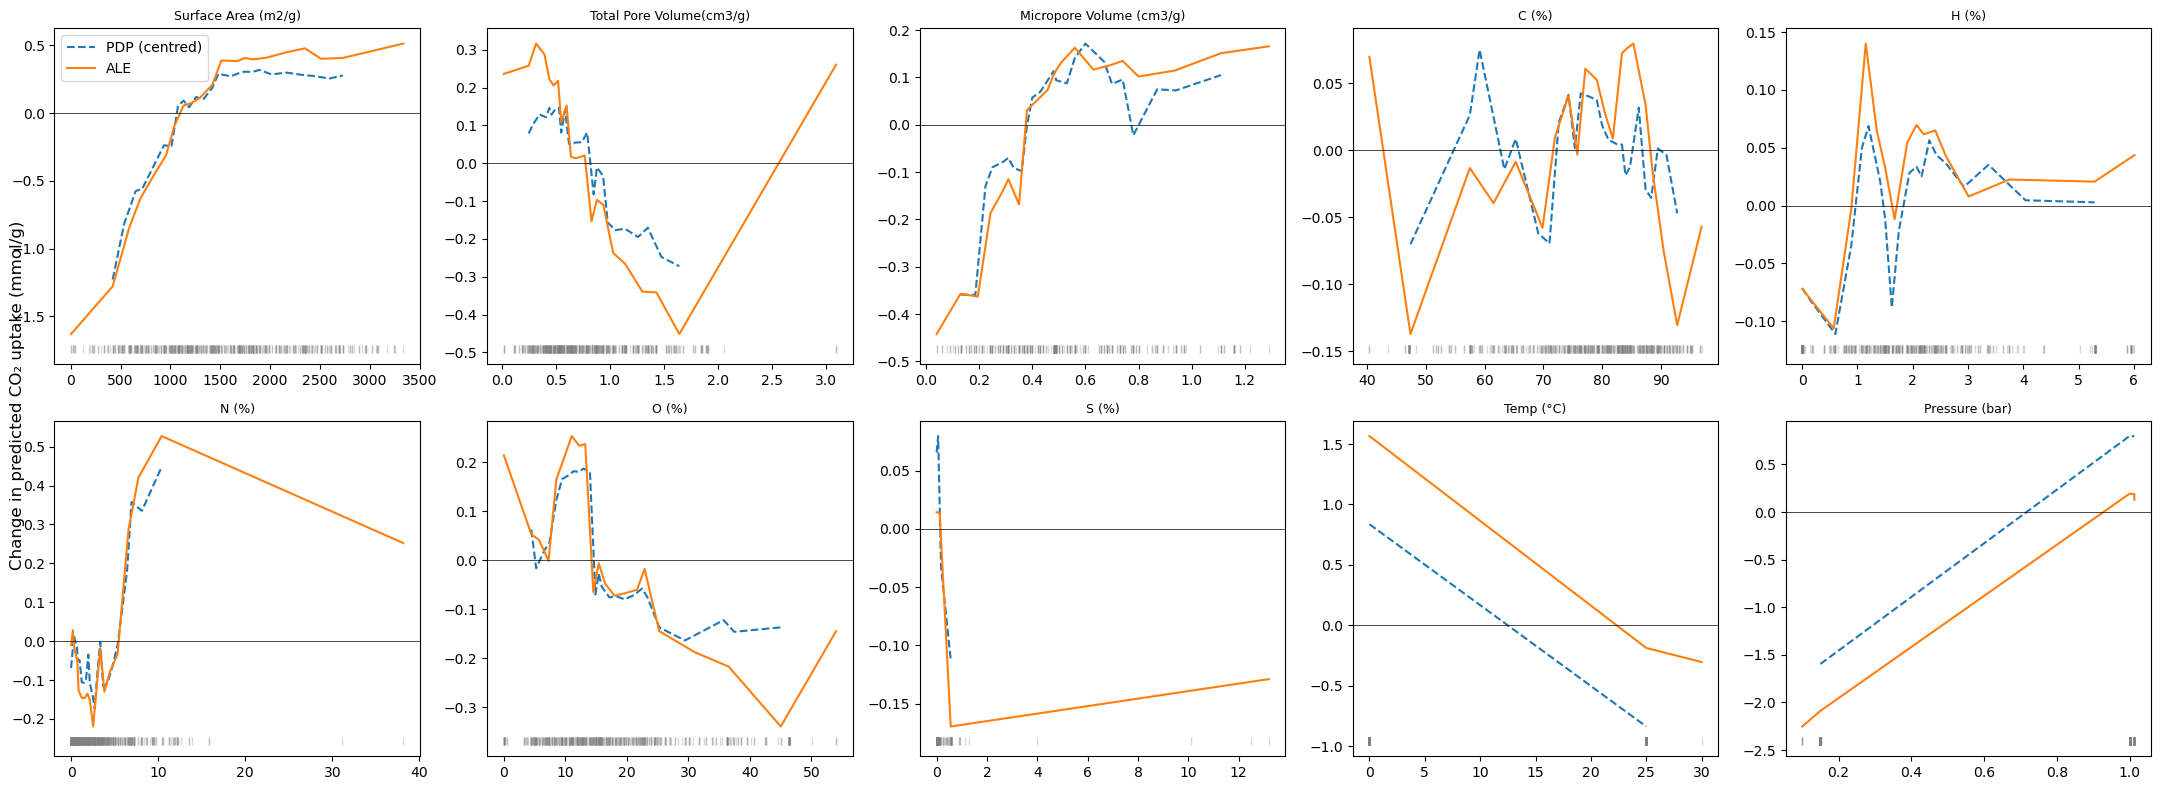

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, feat in zip(axes.ravel(), FEATURES):
    g, p = pdp_1d(ensemble_predict, X, feat)
    e, a = ale_1d(ensemble_predict, X, feat)
    ax.plot(g, p - p.mean(), "--", label="PDP (centred)")
    ax.plot(e, a, label="ALE")
    ax.plot(X[feat].dropna(), np.full(X[feat].notna().sum(), ax.get_ylim()[0]), "|", color="gray", alpha=0.3)
    ax.set_title(feat, fontsize=9)
    ax.axhline(0, color="k", lw=0.5)
axes[0, 0].legend()
fig.supylabel("Change in predicted CO₂ uptake (mmol/g)")
plt.tight_layout()
plt.savefig(RESULTS / "12_pdp_ale.png", dpi=150)
plt.show()